# Part 1

## Task 1

Setup first.

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

date_columns = ['last_scraped', 'calendar_last_scraped', 'first_review', 'last_review']

listings = pd.read_csv('../listings_clean.csv', parse_dates=date_columns)

print(listings.shape)

(4574, 73)


Histogram for number_of_reviews.

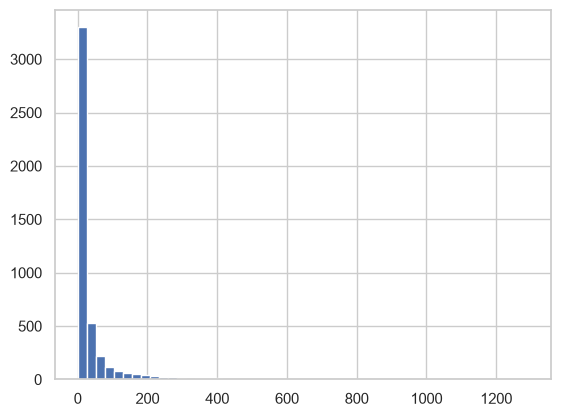

In [ ]:
fig, ax = plt.subplots()

ax.hist(listings['number_of_reviews'].dropna(), bins=50)

plt.show()

We can see that most listings do not have any reviews (0).

Histogram (with `seaborn` on the same thing).

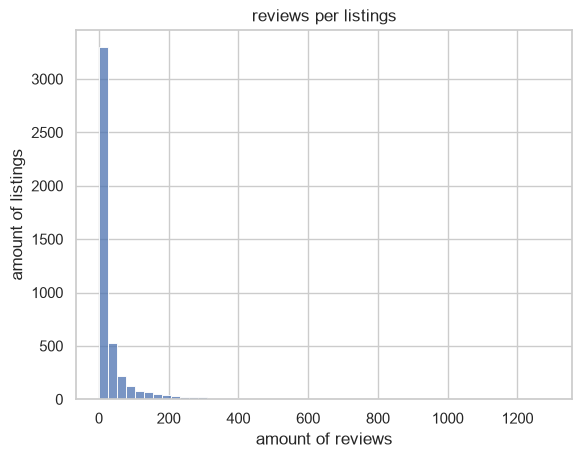

In [15]:
fig, ax = plt.subplots()

sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=ax)

#title
ax.set_title('reviews per listings')

#x
ax.set_xlabel('amount of reviews')

#y
ax.set_ylabel('amount of listings')

plt.show()

The second alternative is simply different in us specifying what the axes represent.

## Task 2

Preparation of data.
**Median**: 9.0
**Mean**: 35.8
**Upper**: 69.5

In [17]:
median = listings['number_of_reviews'].median()
mean = listings['number_of_reviews'].mean()

q1 = listings['number_of_reviews'].quantile(0.25)
q3 = listings['number_of_reviews'].quantile(0.75)

iqr = q3 - q1

upper = q3 + 1.5 * iqr

print(f"median: {median.round(1)}, mean: {mean.round(1)}, upper: {upper.round(1)}")

median: 9.0, mean: 35.8, upper: 69.5


Application of data to a histogram.

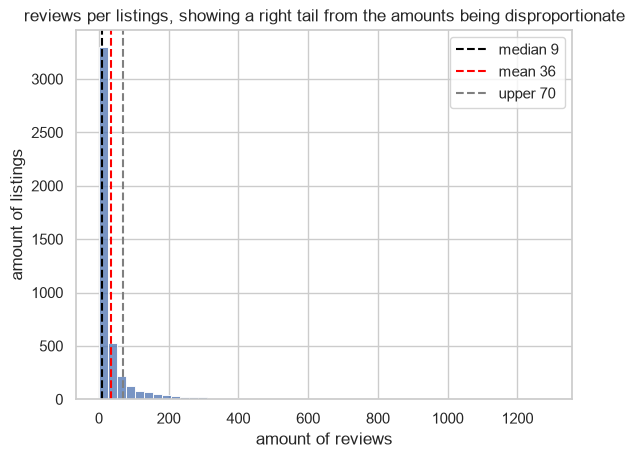

In [22]:
fig, ax = plt.subplots()

sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=ax)

ax.axvline(median, color='black', linestyle='--', label=f'median {median:,.0f}')
ax.axvline(mean, color='red', linestyle='--', label=f'mean {mean:,.0f}')
ax.axvline(upper, color='gray', linestyle='--', label=f'upper {upper:,.0f}')

ax.set_title('reviews per listings, showing a right tail from the amounts being disproportionate')
ax.set_xlabel('amount of reviews')
ax.set_ylabel('amount of listings')
ax.legend()

plt.show()

The line furthest to the right is the upper fence (the gray line), 
and it is because it indicates where the listings with more rating starts, which are fewer - and therefore more rare - in this case.

## Task 3

New column.

In [23]:
listings['reviews_outlier'] = listings['number_of_reviews'] > upper

Charts.
(3992 non-outliers, 582 outliers.)

582
3992


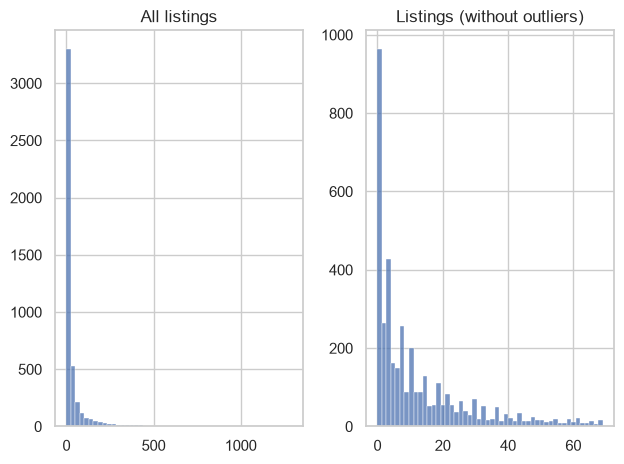

In [27]:
print(len(listings[listings['reviews_outlier']]))
print(len(listings[~listings['reviews_outlier']]))

fig, axes = plt.subplots(1, 2)

sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=axes[0])
sns.histplot(data=listings[~listings['reviews_outlier']],x='number_of_reviews', bins=50, ax=axes[1])

axes[0].set_title('All listings')
axes[1].set_title('Listings (without outliers)')

for ax in axes:
    ax.set_xlabel('')
    ax.set_ylabel('')

plt.tight_layout()
plt.show()

The right chart shows the otherwise less/not visible values, which are undermined by the outliers otherwise (look at the left chart).
As the expected answer hints show, this matches up, as the tail ends at around 1293 and 67 here as well.

## Task 4

Boxplot structuring for room type and number of reviews.

In [ ]:
types_of_interest = listings[listings['room_type'].isin(['Entire home/apt', 'Private room'])]

#Medians being 8 and 12
print(listings[listings['room_type'] == 'Entire home/apt']['number_of_reviews'].median())
print(listings[listings['room_type'] == 'Private room']['number_of_reviews'].median())

8.0
12.0


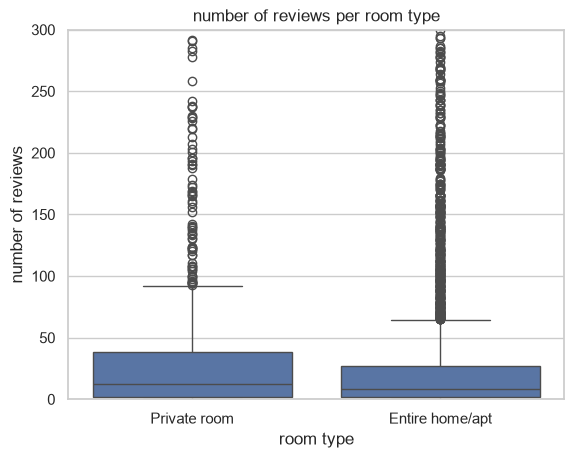

In [36]:
fig, ax = plt.subplots()

sns.boxplot(data=types_of_interest, x='room_type', y='number_of_reviews', ax=ax)

ax.set_ylim(0, 300)
ax.set_title('number of reviews per room type')
ax.set_xlabel('room type')
ax.set_ylabel('number of reviews')

plt.show()

The median is higher on Private rooms, and the box itself encompasses a bigger range.

90 listings outside of the 300 limit.

In [44]:
types_of_interest[types_of_interest['number_of_reviews'] > 300].count()

id                   90
listing_url          90
scrape_id            90
last_scraped         90
source               14
                     ..
days_since_review    90
has_reviews          90
shared_bath          90
bathrooms_count      90
reviews_outlier      90
Length: 74, dtype: int64

## Task 5

Countplot of listings per room_type.

### a)

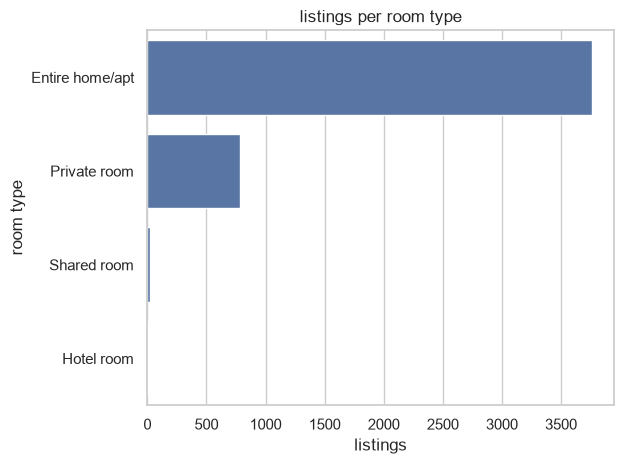

In [46]:
order = listings['room_type'].value_counts().index

fig, ax = plt.subplots()

sns.countplot(data=listings, y='room_type', order=order, ax=ax)

ax.set_title('listings per room type')
ax.set_xlabel('listings')
ax.set_ylabel('room type')

plt.tight_layout()
plt.show()

### b)

Median and count in one go for **number_of_reviews** per **neighbourhood_cleansed**.

In [47]:
neigh_review = (
    listings.groupby('neighbourhood_cleansed')['number_of_reviews']
    .agg(['median', 'count'])
    .sort_values('median', ascending=False)
    .reset_index()
)

Labels.

In [48]:
neigh_review['label'] = neigh_review['neighbourhood_cleansed'] + '(' + neigh_review['count'].astype(str) + ')'

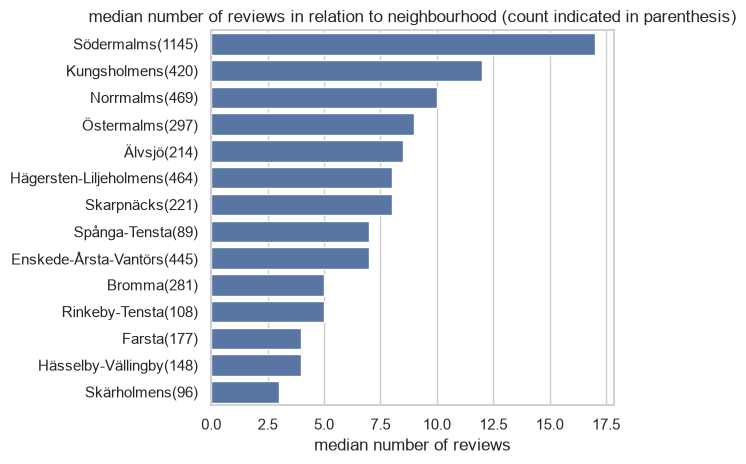

In [49]:
fig, ax = plt.subplots()

sns.barplot(data=neigh_review, x='median', y='label', ax=ax)

ax.set_title('median number of reviews in relation to neighbourhood (count indicated in parenthesis)')
ax.set_xlabel('median number of reviews')
ax.set_ylabel('')

plt.tight_layout()
plt.show()

The neighbourhood with highest median is Södermalms, at around 17. Södermalm is also the neighbourhood with most listings.

## Task 6

Without coloring (room type).

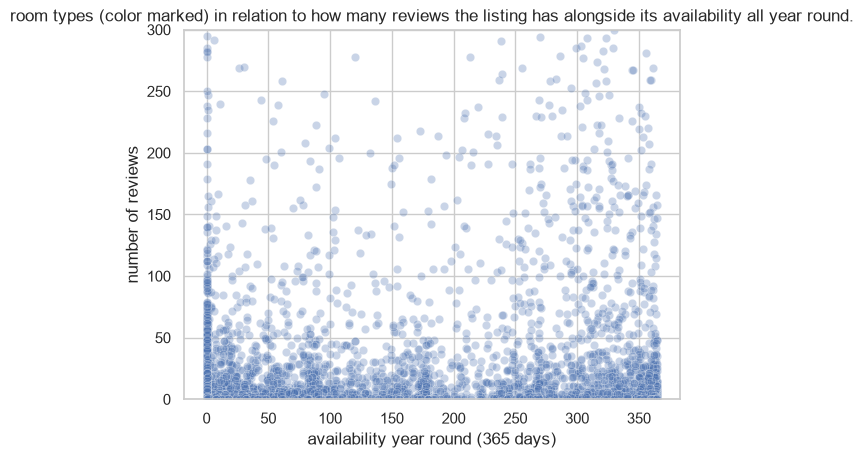

In [52]:
fig, ax = plt.subplots()

sns.scatterplot(data=listings, x='availability_365', y='number_of_reviews', alpha=0.3, ax=ax)

ax.set_ylim(0, 300)

#wip this
ax.set_title('room types (color marked) in relation to how many reviews the listing has alongside its availability all year round.')
ax.set_xlabel('availability year round (365 days)')
ax.set_ylabel('number of reviews')


plt.show()

No clear correlation, most values fall to the bottom however. 
What can be seen is that the listings with extreme values are quite concentrated, but there is
no clear or super-linear trend beyond that. 

With coloring (room type).

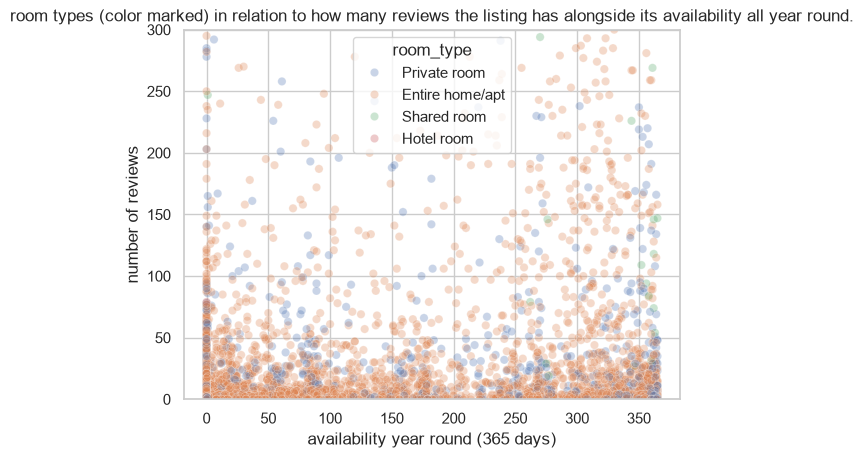

In [53]:
fig, ax = plt.subplots()

sns.scatterplot(data=listings, x='availability_365', y='number_of_reviews', hue='room_type', alpha=0.3, ax=ax)

ax.set_ylim(0, 300)

#wip this
ax.set_title('room types (color marked) in relation to how many reviews the listing has alongside its availability all year round.')
ax.set_xlabel('availability year round (365 days)')
ax.set_ylabel('number of reviews')


plt.show()

Although the entries having "Entire home/apt" as the more common room type among the listings,
it becomes quite clear that all the ratings regardless of room type are quite spread out.
Blue here and there, and the same with orange.

## Task 7

### a)

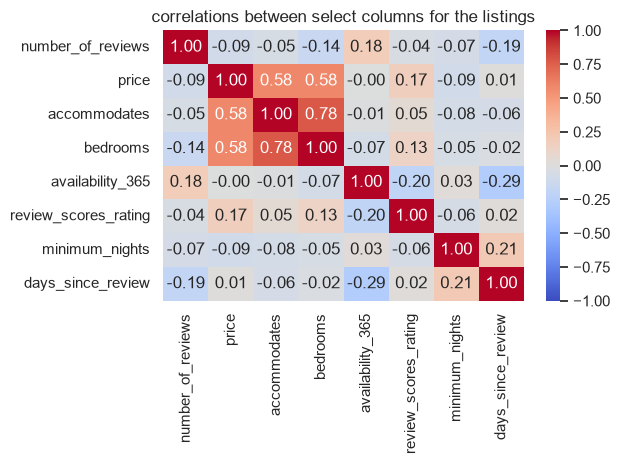

In [57]:
columns = ['number_of_reviews', 'price', 'accommodates', 'bedrooms', 'availability_365', 'review_scores_rating', 'minimum_nights', 'days_since_review']

corr = listings[columns].corr()

fig, ax = plt.subplots()

sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, ax=ax)

ax.set_title('correlations between select columns for the listings')

plt.tight_layout()
plt.show()

Essentially the only more significant correlations are between the columns for price, accommodation and bedrooms.
Like, the more bedrooms, the more people are allowed in the same listing at once, and the price will be higher.
0.58 and 0.78 are the noteworthy values here.

### b)

listings per year of the last no review - last_review.dt.year, 
line chaato o tsukutte.

saigo no koto no tokubetsu na koto wa nani? imi wa?

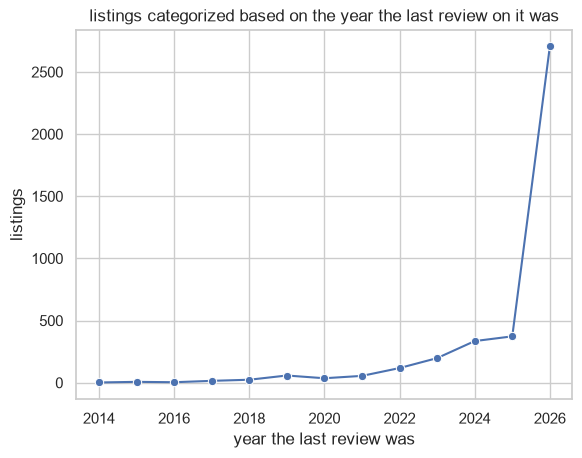

In [59]:
last_review_per_year = listings['last_review'].dt.year.value_counts().sort_index()

fig, ax = plt.subplots()

sns.lineplot(x=last_review_per_year.index, y=last_review_per_year.values, marker='o', ax=ax)

ax.set_title('listings categorized based on the year the last review on it was')
ax.set_xlabel('year the last review was')
ax.set_ylabel('listings')

plt.show()

Very few, but a handful, of entries have not had any new reviews in quite a long time.
It does not have to mean the listing has not been used at all.
However, interestingly enough, most listings are actually have been reviewed within recent time.
Like the teacher mentioned, the data for these listings does not comprise the entirety of 2026.